In [17]:
import numpy as np
import netCDF4 as nc

import matplotlib.pyplot as plt
from pathlib import Path
import xarray as xr

In [2]:
file = Path("~/SouthEnglandPrecipitation.nc").expanduser()
dataset = nc.Dataset(str(file), mode="r")

dict_keys(['number', 'valid_time', 'latitude', 'longitude', 'expver', 'cp', 'lsp'])
(1042, 10, 12)


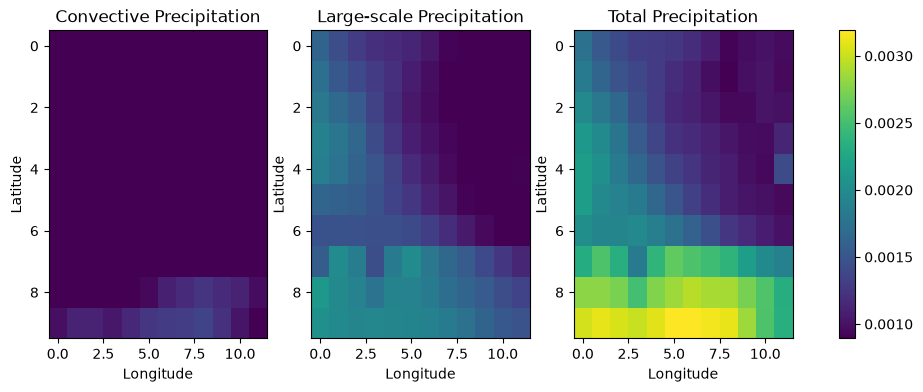

In [16]:
with nc.Dataset(str(file), "r") as ds:
    print(ds.variables.keys())

    lat = ds.variables["latitude"][:]
    lon = ds.variables["longitude"][:]
    convp = ds.variables["cp"][:]
    lsp = ds.variables["lsp"][:]
    tot = convp + lsp
    assert tot.shape == lsp.shape
    print(tot.shape)

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

    heatmaps = [convp[0], lsp[0], tot[0]]
    titles = ["Convective Precipitation", "Large-scale Precipitation", "Total Precipitation"]
    vmin, vmax = min(tot[0].flatten()), max(tot[0].flatten())

    for ax, hm, title in zip(axes, heatmaps, titles):
        im = ax.imshow(hm, aspect='auto', vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")

    fig.colorbar(im, ax=axes, orientation='vertical')
    #plt.tight_layout()
    plt.show()

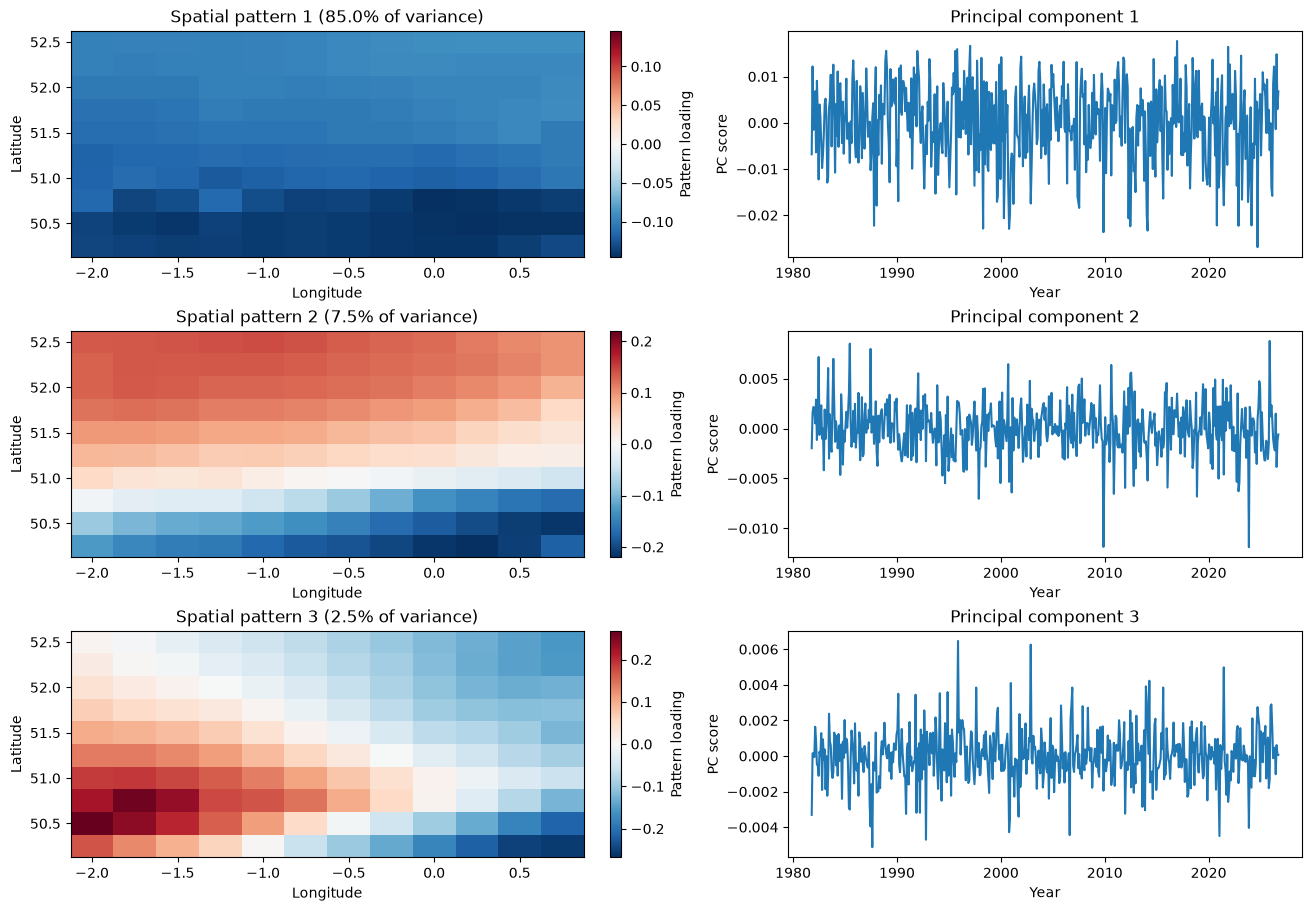

In [51]:
# PCA of total precipitation across the 2D grid
precip = np.ma.filled(tot, np.nan).astype(float)
n_time, n_lat, n_lon = precip.shape
grid = precip.reshape(n_time, -1)

# Keep grid cells with a value at every time step.
valid_cells = np.isfinite(grid).all(axis=0)
if valid_cells.sum() < 2:
    raise ValueError("PCA needs at least two grid cells with complete data")
X = grid[:, valid_cells].copy()

# Remove each grid cell's mean for each calendar month.
# Use the time coordinate trimmed alongside tot, not the full dataset time axis.
time_var = dataset.variables["valid_time"]
if len(precip_time) != n_time:
    raise ValueError("precip_time and tot have different lengths; rerun the trimming cell first")
dates = nc.num2date(
    precip_time,
    units=time_var.units,
    calendar=getattr(time_var, "calendar", "standard"),
)
months = np.array([date.month for date in dates])
years = np.array([date.year + (date.month - 0.5) / 12 for date in dates])

for month in range(1, 13):
    rows = months == month
    X[rows] -= X[rows].mean(axis=0)

# Give grid cells approximately equal weight by area.
latitude_grid = np.broadcast_to(np.asarray(lat)[:, None], (n_lat, n_lon))
weights = np.sqrt(np.cos(np.deg2rad(latitude_grid.ravel()[valid_cells])))
X_weighted = X * weights

# Singular value decomposition gives the principal components and spatial patterns.
U, singular_values, Vt = np.linalg.svd(X_weighted, full_matrices=False)
n_components = 3
pcs = U[:, :n_components] * singular_values[:n_components]
variance_fraction = singular_values**2 / np.sum(singular_values**2)

# Put the spatial patterns back onto the latitude-longitude grid.
patterns = np.full((n_components, n_lat * n_lon), np.nan)
patterns[:, valid_cells] = Vt[:n_components] / weights
patterns = patterns.reshape(n_components, n_lat, n_lon)

fig, axes = plt.subplots(n_components, 2, figsize=(13, 9), constrained_layout=True)

for i in range(n_components):
    limit = np.nanmax(np.abs(patterns[i]))
    image = axes[i, 0].pcolormesh(
        lon, lat, patterns[i],
        shading="auto", cmap="RdBu_r", vmin=-limit, vmax=limit
    )
    axes[i, 0].set(
        title=f"Spatial pattern {i + 1} ({variance_fraction[i]:.1%} of variance)",
        xlabel="Longitude", ylabel="Latitude"
    )
    fig.colorbar(image, ax=axes[i, 0], label="Pattern loading")

    axes[i, 1].plot(years, pcs[:, i])
    axes[i, 1].set(
        title=f"Principal component {i + 1}",
        xlabel="Year", ylabel="PC score"
    )

plt.show()

In [19]:
indexfile = Path("~/nino34index.nc").expanduser()

In [20]:
index = nc.Dataset(str(indexfile), "r")

In [21]:
print(index.variables.keys())

dict_keys(['TIME', 'NINO34'])


In [37]:
time = index.variables["TIME"][:]
nivs = index.variables["NINO34"][:]
print(time.shape, nivs.shape)
print(time[0], nivs[1])

(2352,) (2352,)
66357.0 -0.19749718760430554


In [ ]:
print(time[2351] - time[0])

16457.0


In [30]:
(time[1]-time[0]) * (len(time) - 1)

np.float64(16457.0)

In [34]:
print(len(time) / 4, (2026 - 1981) * 12)

588.0 540


In [38]:
index.variables["TIME"]

<class 'netCDF4.Variable'>
float64 TIME(TIME)
    long_name: Time
    units: days since 1800-01-01 00:00:00
    axis: T
    calendar: gregorian
    standard_name: time
unlimited dimensions: TIME
current shape = (2352,)
filling on, default _FillValue of 9.969209968386869e+36 used

In [39]:
time[1] - time[0]

np.float64(7.0)

In [40]:
nivs[0]

np.float64(-0.32023328450106764)

In [41]:
index.variables["NINO34"]

<class 'netCDF4.Variable'>
float64 NINO34(TIME)
    missing_value: -1e+34
    _FillValue: -1e+34
    long_name: Nino 3.4 Region SSTA (base period 1991-2020, data from OISST)
    units: degC
unlimited dimensions: TIME
current shape = (2352,)
filling on

In [48]:
from datetime import datetime
import numpy as np
import netCDF4 as nc

precip_time_var = dataset.variables["valid_time"]
all_precip_time = precip_time_var[:]
calendar = getattr(precip_time_var, "calendar", "standard")

start_num = nc.date2num(
    datetime(1981, 9, 6), precip_time_var.units, calendar=calendar
)
# Exclusive upper bound includes every time on 2026-09-27.
end_num = nc.date2num(
    datetime(2026, 9, 28), precip_time_var.units, calendar=calendar
)

start = int(np.searchsorted(all_precip_time, start_num, side="left"))
stop = int(np.searchsorted(all_precip_time, end_num, side="left"))
if start >= stop:
    raise ValueError("No precipitation observations in the requested date range")

# Read from the dataset each time, so rerunning this cell slices correctly.
precip_time = all_precip_time[start:stop]
convp = dataset.variables["cp"][start:stop]
lsp = dataset.variables["lsp"][start:stop]
tot = convp + lsp

dates = nc.num2date(
    precip_time, precip_time_var.units, calendar=calendar
)
dataset_last = nc.num2date(
    all_precip_time[-1], precip_time_var.units, calendar=calendar
)

print("Dataset's last precipitation date:", dataset_last)
print("Selected precipitation dates:", dates[0], "to", dates[-1])
print("Precipitation maps:", len(tot))

Dataset's last precipitation date: 2026-10-01 06:00:00
Selected precipitation dates: 1981-10-01 06:00:00 to 2026-09-01 06:00:00
Precipitation maps: 540


In [47]:
import pandas as pd

enso_dates = (pd.Timestamp("1800-01-01") + pd.to_timedelta(time, unit="D"))
print(enso_dates[0], enso_dates[-1])

1981-09-06 00:00:00 2026-09-27 00:00:00


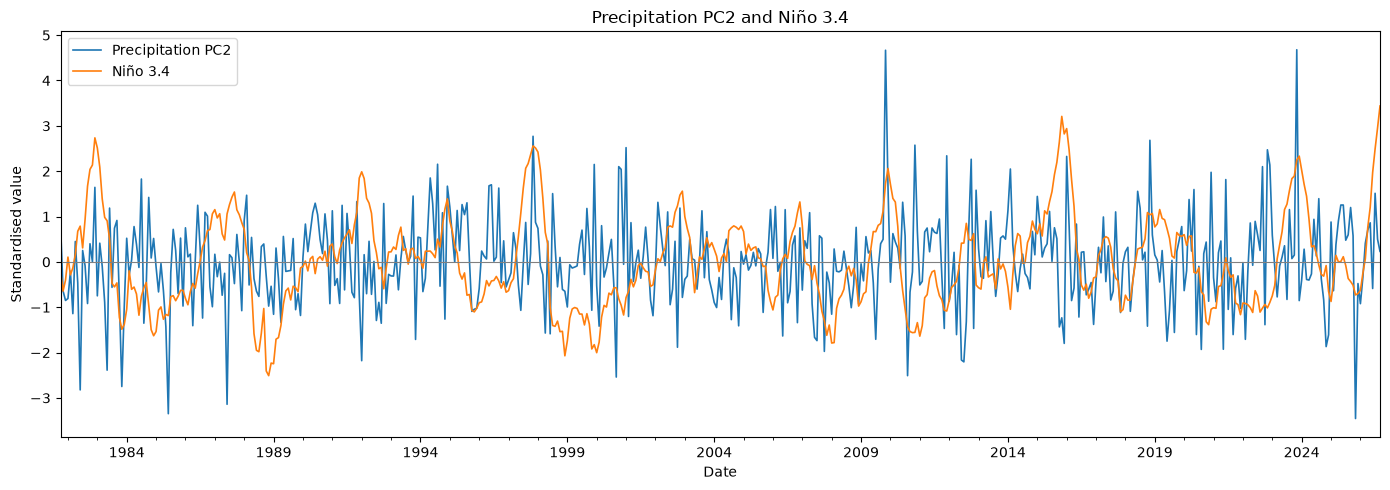

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pc_dates = nc.num2date(
    precip_time,
    units=precip_time_var.units,
    calendar=calendar,
)
if len(pcs) != len(pc_dates):
    raise ValueError("Rerun PCA on the trimmed precipitation data first")

pc_months = pd.to_datetime([d.strftime("%Y-%m-%d") for d in pc_dates])
pc1 = pd.Series(pcs[:, 0], index=pc_months, name="Precipitation PC1")
pc2 = -pd.Series(pcs[:, 1], index=pc_months, name="Precipitation PC2")

enso_monthly = pd.Series(
    np.ma.filled(nivs, np.nan),
    index=pd.DatetimeIndex(enso_dates),
    name="Niño 3.4",
).resample("MS").mean()

aligned = pd.concat(
    [pc2, enso_monthly], axis=1, join="inner"
).dropna()

# Put the different units on a comparable plotting scale.
scaled = (aligned - aligned.mean()) / aligned.std()

fig, ax = plt.subplots(figsize=(14, 5))
scaled.plot(ax=ax, linewidth=1.2)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set(
    title="Precipitation PC2 and Niño 3.4",
    xlabel="Date",
    ylabel="Standardised value",
)
plt.tight_layout()
plt.show()

In [57]:
r = aligned["Precipitation PC2"].corr(
    aligned["Niño 3.4"],
    method="pearson",
)

print(f"Pearson r = {r:.3f} ({len(aligned)} paired months)")

Pearson r = 0.094 (540 paired months)
